# RRUFF Raman exports: what the eight archives hold

The eight archives read here were downloaded from
<https://www.rruff.net/zipped_data_files/raman/> on **2026-09-28** and extracted to
`~/Desktop`, one directory per archive. Together they are RRUFF's published Raman
grid: a quality tier crossed with an orientation, plus the low-resolution broad-scan
export. Every file holds one measured spectrum as plain text, a `##KEY=value` header
block above the data rows.

The reference for the collection is Lafuente B, Downs R T, Yang H, Stone N (2015),
*The power of databases: the RRUFF project*, in *Highlights in Mineralogical
Crystallography*, De Gruyter, 1-30.

What this notebook answers, in order:

1. one sentence describing each archive;
2. the header fields that the files in each archive carry;
3. how many files are RAW, Processed, or something else, and how that splits per
   archive;
4. how RRUFF records the mineral identification behind each label;
5. the distribution of excitation wavelength.

Every number below is counted from the files themselves. Nothing is quoted from a
README, and the only path assumed is the directory holding the archives.

## 1. The eight archives

RRUFF publishes Raman spectra one archive per cell of a two-way grid, and the two
axes of that grid describe different things about a sample.

**Quality tier.** *Excellent*, *fair* and *poor* are a judgement on the spectrum
itself: how cleanly it resolved the mineral's bands. *Unrated* means no such
judgement was recorded.

**Orientation.** An *oriented* measurement mounts the crystal on a pin at a known
angle to the laser, so the header records the mount and the laser direction, and the
spectrum is one slice through the mineral's polarisation behaviour. An *unoriented*
measurement lets the laser meet the crystal at an undefined angle, and what comes
back is a single mixed spectrum.

The low-resolution archive sits outside that grid: a broad scan that runs far past
the usual window, trading resolution for coverage. It is unoriented throughout.

There is no `poor_oriented` archive. At the poor tier every Raman spectrum RRUFF
releases is unoriented, which is why the grid has seven cells and not eight.

In [1]:
from __future__ import annotations

import os
import re
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

%matplotlib inline


def find_repo_root(start: Path) -> Path:
    """Walk up from a directory until the file that marks the repository root."""
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"no pyproject.toml in or above {start}")


# The notebook may be run from the repository root or from notebooks/, so the package
# is put on the path from whichever directory is found rather than assumed.
REPO_ROOT = find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src import paths

# Categorical slots are taken in a fixed order and never cycled. The four were checked
# with a colour-vision-deficiency validator: worst adjacent pair dE 9.1 (protan), worst
# normal-vision pair dE 22.9. Aqua and yellow also sit below 3:1 contrast on this
# surface, so every chart using them carries visible value labels as well as colour.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
SURFACE = "#fcfcfb"

# Magnitude gets one hue, light to dark, never a rainbow.
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "rruff_blues", [SURFACE, "#cfe3f7", "#8cbdf0", "#4a92e0", BLUE, "#1b4f92"])

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,  # grid behind the marks
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "text.color": INK,
    "font.size": 9,
    "legend.frameon": False,
    "figure.dpi": 110,
})

# The eight archive directories, in the order the notebook reports them.
ARCHIVES = [
    "LR-Raman",
    "excellent_oriented",
    "excellent_unoriented",
    "fair_oriented",
    "fair_unoriented",
    "poor_unoriented",
    "unrated_oriented",
    "unrated_unoriented",
]

# The archives are extracted side by side. Point RRUFF_DESKTOP elsewhere if they are
# not under ~/Desktop.
DESKTOP = Path(os.environ.get("RRUFF_DESKTOP", Path.home() / "Desktop")).expanduser()

# Header keys in the order RRUFF writes them, which is the order to read them in.
KEY_ORDER = [
    "NAMES", "RRUFFID", "IDEAL CHEMISTRY", "LOCALITY", "OWNER", "SOURCE", "DESCRIPTION",
    "STATUS", "URL", "MEASURED CHEMISTRY", "PIN_ID", "ORIENTATION",
    "DIFFRACTION SAMPLE DESCRIPTION", "CELL PARAMETERS", "FILETYPE", "RAMAN WAVELENGTH",
]

HEADER_LINE = re.compile(r"^##([^=]+)=(.*)$")
NUMBER = re.compile(r"[0-9]+(?:\.[0-9]+)?")
LEADING = "+-."

missing = [name for name in ARCHIVES if not (DESKTOP / name).is_dir()]
if missing:
    present = sorted(entry.name for entry in DESKTOP.iterdir() if entry.is_dir())
    raise FileNotFoundError(
        f"{DESKTOP} does not hold {missing}. Set RRUFF_DESKTOP to the directory that "
        f"holds the archives. Directories that are there: {present}"
    )
print(f"reading the eight archives from {DESKTOP}")

reading the eight archives from /home/raj/Desktop


## 2. Reading the pool

A file is a `##KEY=value` block, then the data rows, then usually a `##END=` line
after the last row. Three things about that block defeat the obvious reader, the one
that reads header fields until the first line that does not start with `##`:

1. **A value can wrap.** When a value is long, RRUFF continues it on the following
   line, and that line carries no `##` of its own. The pin's fiducial note wraps this
   way, and one wavelength value ends with a bare `800, -` on a line of its own.
2. **The block can repeat.** Some files carry the sample block and then a second,
   measurement-specific block, so a key that appears twice should end up holding the
   later value.
3. **A few files add notes.** Seven files carry lines that start with a single `#`
   between the block and the data, and they are four different things wearing the same
   prefix: a prose note about the measurement and who took it, a JSON dump of the
   instrument's saved configuration, a key-value dump of that measurement's acquisition
   settings, and an inline `#Wave,#Intensity` column header. The settings dump writes
   `µ` and the superscript of `cm-1` as bare latin-1 bytes rather than as UTF-8, which
   is why a strict decode of three files raises.

Stopping at the first non-`##` line loses `FILETYPE` and `RAMAN WAVELENGTH` on 492
excellent_oriented and 236 unrated_oriented files, and those two fields are exactly
what the rest of this notebook counts. So the block is read up to the first data row
instead, and any other stray line is a continuation of the key above it. A data row is
exactly two numbers, which is what separates it from a continuation that happens to
begin with a digit.

In [2]:
def read_spectrum(path):
    """Read one export: its header fields, and facts about its data block.

    A file is a ##KEY=value block, then the data rows, then usually a ##END= line
    after the last one. Three things about that block defeat a reader that stops
    at the first line not starting with ##:

    - a value can wrap onto the following line, which then carries no ## of its
      own (a pin's fiducial note does this, and one wavelength value ends with a
      bare "800, -" on a line of its own);
    - the block can repeat, the measurement-specific copy second, so a later key
      has to overwrite an earlier one;
    - LR-Raman files add #-prefixed acquisition notes between the block and the
      data.

    So the block runs to the first data row, and any other stray line is a
    continuation of the key above it. Stopping at the first non-## line instead
    loses FILETYPE and RAMAN WAVELENGTH on 492 excellent_oriented and 236
    unrated_oriented files.

    A data row is exactly two numbers, which is what separates it from a
    continuation that happens to begin with a digit. Text is decoded as UTF-8,
    which is what RRUFF writes; three files in the pool carry a stray latin-1
    byte inside a comment, so undecodable bytes are replaced rather than raising.
    Lines are split on newline alone: str.splitlines() also breaks on the control
    characters that occur inside a few locality names.
    """
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8")
        encoding = "utf-8"
    except UnicodeDecodeError:
        text = raw.decode("utf-8", errors="replace")
        encoding = "utf-8, one byte replaced"
    text = text.replace("\r\n", "\n")
    lines = text.split("\n")

    header, last = {}, None
    wrapped = repeated = notes = 0
    separator = ""
    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is None:
                notes += 1
                continue
            key, value = match.group(1).strip(), match.group(2).strip()
            if key == "END":
                body = position + 1
                break
            if key in header:
                repeated += 1
            header[key] = value
            last = key
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    separator = ("tab" if "\t" in line
                                 else "comma" if "," in line else "space")
                    break
        if last is not None:
            header[last] = header[last] + " " + stripped
            wrapped += 1

    points, first_row, last_row = 0, None, None
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped:
            continue
        if stripped.startswith("##END"):
            break
        if stripped[0] == "#":
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            points += 1
            if first_row is None:
                first_row = stripped
            last_row = stripped

    x_min = float(first_row.replace(",", " ").split()[0]) if first_row else None
    x_max = float(last_row.replace(",", " ").split()[0]) if last_row else None
    if x_min is not None and x_max is not None and x_min > x_max:
        x_min, x_max = x_max, x_min

    layout = {
        "points": points, "x_min": x_min, "x_max": x_max,
        "wrapped_values": wrapped, "repeated_keys": repeated, "comment_notes": notes,
        "separator": separator, "crlf": b"\r\n" in raw,
        "encoding": encoding,
    }
    return header, layout

In [3]:
# How a STATUS sentence is grouped by what the identification rests on. The sentence
# is free text, so the group is decided by which analyses it names. An identification
# RRUFF has not confirmed is its own group, because a label it does not stand behind
# is a different kind of ground truth from one it does.
FAMILIES = ["XRD plus chemistry", "XRD alone", "Non-X-ray only", "Not yet confirmed"]


def status_family(status: str) -> str:
    """Group one STATUS sentence by what the identification rests on."""
    text = status.lower()
    if "not yet confirmed" in text or text.strip() == "unconfirmed":
        return "Not yet confirmed"
    if "x-ray diffraction" in text:
        return "XRD plus chemistry" if "chemical analysis" in text else "XRD alone"
    return "Non-X-ray only"


started = time.time()
records = []
for archive in ARCHIVES:
    for path in sorted((DESKTOP / archive).glob("*.txt")):
        header, layout = read_spectrum(path)
        filetype = header.get("FILETYPE", "")
        found = NUMBER.search(header.get("RAMAN WAVELENGTH", ""))
        records.append({
            "archive": archive,
            "path": str(path),
            "name": path.stem,
            # A measurement is the file name without its last two fields, the export
            # kind and the content hash. Two files are twins of one measurement exactly
            # when this key matches, so it is the unit a split has to group on.
            "measurement": "__".join(path.stem.split("__")[:6]),
            "mineral": header.get("NAMES", ""),
            "rruff_id": header.get("RRUFFID", ""),
            "filetype": filetype,
            "kind": "RAW" if "RAW" in filetype.upper() else "Processed",
            "wavelength_reported": header.get("RAMAN WAVELENGTH", ""),
            "wavelength_nm": float(found.group()) if found else np.nan,
            "status": header.get("STATUS", ""),
            "header": header,
            "keys": frozenset(header),
            **layout,
        })

index = pd.DataFrame.from_records(records)
index["family"] = index.status.map(status_family)
index["spacing"] = (index.x_max - index.x_min) / (index.points - 1).replace(0, np.nan)

print(f"read {len(index):,} files in {time.time() - started:.1f}s")
print(f"columns: {', '.join(c for c in index.columns if c not in {'header', 'keys'})}")
index[[
    "archive", "mineral", "rruff_id", "kind", "wavelength_nm", "status", "points",
    "x_min", "x_max", "spacing",
]].head()

read 38,056 files in 23.2s
columns: archive, path, name, measurement, mineral, rruff_id, filetype, kind, wavelength_reported, wavelength_nm, status, points, x_min, x_max, wrapped_values, repeated_keys, comment_notes, separator, crlf, encoding, family, spacing


,archive,mineral,rruff_id,kind,wavelength_nm,status,points,x_min,x_max,spacing
0,LR-Raman,Abellaite,R250095,RAW,532.0,The identification of this mineral has been co...,10128,50.00000,4000.000,0.390046
1,LR-Raman,Abelsonite,R070007,RAW,532.0,The identification of this mineral is confirme...,3315,175.00320,6565.942,1.928467
2,LR-Raman,Abelsonite,R070007,RAW,785.0,The identification of this mineral is confirme...,2110,233.31280,4300.450,1.928467
3,LR-Raman,Abhurite,R060227,RAW,532.0,The identification of this mineral is confirme...,3394,86.13089,6629.419,1.928467
4,LR-Raman,Abhurite,R060227,RAW,780.0,The identification of this mineral is confirme...,2230,82.56664,4381.119,1.928467


In [4]:
# Two files, shown raw. The first is ordinary. The second is one of the 728 whose
# header wraps and repeats, which is the case that costs a naive reader the FILETYPE
# and RAMAN WAVELENGTH fields.
plain = index.loc[(index.archive == "poor_unoriented") & (index.wrapped_values == 0)].iloc[0]
wrapped = index.loc[(index.archive == "excellent_oriented") & (index.repeated_keys > 0)].iloc[0]

for label, row, span in [
    ("an ordinary file", plain, (0, 19)),
    ("a file whose header wraps and repeats", wrapped, (8, 21)),
]:
    lines = Path(row.path).read_text(encoding="utf-8", errors="replace")
    lines = lines.replace("\r\n", "\n").split("\n")
    print(f"=== {label}: {row.path.rsplit('/', 1)[-1]}")
    for number in range(*span):
        print(f"{number + 1:4d}| {lines[number]!r}")
    print("     parsed header:")
    for key, value in row.header.items():
        print(f"       {key:32s} {value[:72]!r}")
    print()

=== an ordinary file: Abramovite__R070037__Raman__532______Raman_Data_Processed__e1f69acda1221acc29245dad1c10.txt
   1| '##NAMES=Abramovite'
   2| '##RRUFFID=R070037'
   3| '##IDEAL CHEMISTRY=Pb_2_SnInBiS_7_'
   4| '##LOCALITY=Kudryaviy Volcano, Iturup Island, Kurilian Archipelago, Russia'
   5| '##OWNER=Michael Scott'
   6| '##SOURCE=Michael Scott'
   7| '##DESCRIPTION=Dark gray metallic twisted and distorted fibers in a radiating aggregate, co-type sample.'
   8| '##STATUS=The identification of this mineral has been confirmed only by single crystal X-ray diffraction'
   9| '##URL=https://www.rruff.net/odr/rruff_sample/R070037'
  10| '##DIFFRACTION SAMPLE DESCRIPTION=Single crystal, powder profile is calculated'
  11| '##CELL PARAMETERS=a: 23.284 b: 5.858 c: 6.055 alpha: 89.49 beta: 87.8 gamma: 90.12 volume: 825.2 crystal system: triclinic'
  12| '##FILETYPE=Raman Processed'
  13| '##RAMAN WAVELENGTH=532'
  14| ''
  15| '150.1822, 0.0000000E+00'
  16| '150.6643, 34.88086'
  17| '151.1

In [5]:
# The note lines, verbatim, one file per kind of note, so the description above can be
# checked against the words rather than taken on trust.
noted = index[index.comment_notes > 0]
shown = set()
for row in noted.itertuples():
    text = Path(row.path).read_bytes().decode("utf-8", errors="replace")
    notes = [line.strip() for line in text.replace("\r\n", "\n").split("\n")
             if line.strip().startswith("#") and not line.strip().startswith("##")]
    signature = notes[0].split("=")[0]
    if signature in shown:
        continue
    shown.add(signature)
    print(f"=== {row.archive}/{row.name[:68]}")
    for note in notes[:6]:
        print(f"    {note[:96]}")
    print(f"    ... {len(notes)} note lines in this file")
    print()

=== LR-Raman/Abellaite__R250095__Broad_Scan__532__0__unoriented__Raman_Data_Raw__
    #Raman spectrum of abellaite directly obtained from dense aggregates of abellaite microcrystals 
    #Horiba Jobin-Yvon LabRam (532 nm); long-working distance 50x objective
    #Authors: Jordi Ibáñez-Insa (GEO3BCN-CSIC) and Sergi Hernández (University of Barcelona).
    ... 3 note lines in this file

=== LR-Raman/Leybovite-K__R250035__Broad_Scan__532__0__unoriented__Raman_Data_Raw
    #exp_cfg={"servo_angle": -14.0, "laser_lim": 100.0, "servo_angle_to": 10.0, "laser_wup": 0.0, "l
    #proc_cfg={"flat_auto_wnd": 200.0, "flat_auto_dr": 4.0, "flat_auto_shift": 5.0, "yconv": 1, "fla
    ... 2 note lines in this file

=== LR-Raman/Miyawakiite-(Y)__R250122__Broad_Scan__532__0__unoriented__Raman_Data
    #Wave,#Intensity
    ... 1 note lines in this file

=== LR-Raman/Suenoite__R250132__Broad_Scan____0__unoriented__Raman_Data_Raw__f3e9
    #Acq. time (s)=	200
    #Accumulations=	3
    #Range (cm-�)=	3000...4

In [6]:
# How much of the pool each hazard actually touches.
by_archive = index.groupby("archive")
hazards = pd.DataFrame({
    "files": by_archive.size(),
    "wrapped values": by_archive.wrapped_values.apply(lambda column: (column > 0).sum()),
    "repeated keys": by_archive.repeated_keys.apply(lambda column: (column > 0).sum()),
    "#-note lines": by_archive.comment_notes.apply(lambda column: (column > 0).sum()),
    "byte replaced": by_archive.encoding.apply(lambda column: (column != "utf-8").sum()),
    "tab-separated": by_archive.separator.apply(lambda column: (column == "tab").sum()),
}).reindex(ARCHIVES)
hazards["CRLF"] = by_archive.crlf.sum().reindex(ARCHIVES)
hazards.loc["all eight"] = hazards.sum()
hazards = hazards.astype(int)

print(f"data row separators: {dict(index.separator.value_counts())}")
print(f"line endings, CRLF: {dict(index.crlf.value_counts())}")
print(f"encodings: {dict(index.encoding.value_counts())}")
print()

# The three files that do not decode as UTF-8, line by line, to show that every byte
# in question sits in a comment and none of them in the numeric data.
print("lines carrying a byte that is not UTF-8:")
for row in index[index.encoding != "utf-8"].itertuples():
    text = Path(row.path).read_bytes().decode("utf-8", errors="replace")
    for line in text.replace("\r\n", "\n").split("\n"):
        if "�" in line:
            kind = "comment" if line.strip().startswith("#") else "DATA ROW"
            print(f"   {row.archive}/{row.mineral:12s} {kind:9s} {line.strip()[:64]!r}")
print()
hazards

data row separators: {'comma': np.int64(37911), 'tab': np.int64(140), 'space': np.int64(5)}
line endings, CRLF: {True: np.int64(38056)}
encodings: {'utf-8': np.int64(38053), 'utf-8, one byte replaced': np.int64(3)}

lines carrying a byte that is not UTF-8:
   LR-Raman/Suenoite     comment   '#Range (cm-�)=\t3000...4000'
   LR-Raman/Suenoite     comment   '#Slit (�m)=\t50'
   LR-Raman/Suenoite     comment   '#Hole (�m)=\t100'
   LR-Raman/Suenoite     comment   '#X (�m)=\t6344.45'
   LR-Raman/Suenoite     comment   '#Y (�m)=\t12021.4'
   fair_unoriented/Suenoite     comment   '#Range (cm-�)=\t30...1200'
   fair_unoriented/Suenoite     comment   '#Slit (�m)=\t50'
   fair_unoriented/Suenoite     comment   '#Hole (�m)=\t100'
   fair_unoriented/Suenoite     comment   '#X (�m)=\t6673.05'
   fair_unoriented/Suenoite     comment   '#Y (�m)=\t10666.6'
   unrated_unoriented/Nannoniite   comment   '#Range (cm-�)=\t100...1200'
   unrated_unoriented/Nannoniite   comment   '#Slit (�m)=\t100'
   unrat

,files,wrapped values,repeated keys,#-note lines,byte replaced,tab-separated,CRLF
archive,,,,,,,
LR-Raman,9941,8,0,4,1,109,9941
excellent_oriented,7668,492,492,0,0,0,7668
excellent_unoriented,11415,1,0,1,0,13,11415
fair_oriented,25,0,0,0,0,0,25
fair_unoriented,2951,0,0,1,1,4,2951
poor_unoriented,1639,0,0,0,0,0,1639
unrated_oriented,3778,236,236,0,0,0,3778
unrated_unoriented,639,3,0,1,1,14,639
all eight,38056,740,728,7,3,140,38056


Read the census above as: the wrapping and repeating is not a general property of the
format, it is concentrated in two archives and touches about one file in sixteen there.
Every file in the pool uses CRLF line endings, which is why the reader normalises them
before splitting, and comma is the data separator in all but 145 files (140 tab, five
space), which a reader that assumes a comma would take as unparseable and return a
spectrum of zero points. The note lines are seven files in four archives, and the
listing above shows every byte a strict UTF-8 decode rejects sitting in one of them,
so a permissive decode costs nothing that matters: no numeric row is affected.

## 3. One sentence per archive

Each sentence below describes one archive. The columns beside it are counted from the
files, so the two can be read together.

In [7]:
DESCRIPTIONS = {
    "LR-Raman":
        "The low-resolution broad-scan export: one unoriented spectrum per measurement, "
        "sampling at about 1.9 cm-1 per point and reaching far past the window the other "
        "archives use, out to about 6600 cm-1 at the extreme.",
    "excellent_oriented":
        "Excellent spectra measured with the crystal held at a known angle to the laser, so "
        "the header carries both the mount (PIN_ID) and the laser direction relative to the "
        "crystal axes (ORIENTATION); the narrowest mineral coverage of the eight, a few names "
        "with many files each.",
    "excellent_unoriented":
        "The unoriented counterpart of the excellent archive: the same quality judgement, but "
        "the laser meets the crystal at an undefined angle, so PIN_ID and ORIENTATION are "
        "absent; the largest archive in the pool, and second only to LR-Raman in the number "
        "of mineral names it covers.",
    "fair_oriented":
        "Fair spectra measured at a known orientation: a vestigial archive of a few dozen "
        "files, every one of them carrying the same confirmed identification string.",
    "fair_unoriented":
        "The unoriented fair-quality export: a middle-sized pool, and like every unoriented "
        "archive it carries a tail of labels RRUFF has not confirmed.",
    "poor_unoriented":
        "The poor-quality export, unoriented throughout, and the archive with the largest "
        "unconfirmed share of any archive; no poor_oriented archive is published upstream, "
        "because at the poor tier every Raman spectrum RRUFF releases is unoriented.",
    "unrated_oriented":
        "Spectra carrying no quality rating but measured at a known orientation; again a "
        "narrow mineral coverage, a dozen or so files per name.",
    "unrated_unoriented":
        "No quality rating and no orientation: the smallest archive, and the one where RAW "
        "files outnumber Processed most sharply, 447 against 192.",
}

per_mineral = index.groupby(["archive", "mineral"]).size().groupby("archive").median()
unconfirmed = (index.assign(flag=index.family == "Not yet confirmed")
               .groupby("archive").flag.mean().mul(100).round(1))

summary = pd.DataFrame({
    "files": index.groupby("archive").size(),
    "minerals": index.groupby("archive").mineral.nunique(),
    "median files per mineral": per_mineral,
    "RAW": index[index.kind == "RAW"].groupby("archive").size(),
    "Processed": index[index.kind == "Processed"].groupby("archive").size(),
    "unconfirmed %": unconfirmed,
    "points (median)": index.groupby("archive").points.median(),
}).reindex(ARCHIVES)

print(f"{len(index):,} files, {index.mineral.nunique():,} mineral names, "
      f"{index.rruff_id.nunique():,} RRUFF ids\n")
display(summary)
for position, archive in enumerate(ARCHIVES, start=1):
    print(f"{position}. {archive}\n   {DESCRIPTIONS[archive]}\n")

38,056 files, 2,511 mineral names, 4,153 RRUFF ids



,files,minerals,median files per mineral,RAW,Processed,unconfirmed %,points (median)
archive,,,,,,,
LR-Raman,9941,2392,3.0,6566,3375,11.7,2228.0
excellent_oriented,7668,216,24.0,3799,3869,0.0,1150.0
excellent_unoriented,11415,1957,4.0,5628,5787,7.3,2407.0
fair_oriented,25,4,6.5,12,13,0.0,1195.0
fair_unoriented,2951,889,2.0,1466,1485,18.6,2361.0
poor_unoriented,1639,533,2.0,829,810,24.4,2376.0
unrated_oriented,3778,217,12.0,1927,1851,0.0,1275.0
unrated_unoriented,639,271,2.0,447,192,19.6,2477.0


1. LR-Raman
   The low-resolution broad-scan export: one unoriented spectrum per measurement, sampling at about 1.9 cm-1 per point and reaching far past the window the other archives use, out to about 6600 cm-1 at the extreme.

2. excellent_oriented
   Excellent spectra measured with the crystal held at a known angle to the laser, so the header carries both the mount (PIN_ID) and the laser direction relative to the crystal axes (ORIENTATION); the narrowest mineral coverage of the eight, a few names with many files each.

3. excellent_unoriented
   The unoriented counterpart of the excellent archive: the same quality judgement, but the laser meets the crystal at an undefined angle, so PIN_ID and ORIENTATION are absent; the largest archive in the pool, and second only to LR-Raman in the number of mineral names it covers.

4. fair_oriented
   Fair spectra measured at a known orientation: a vestigial archive of a few dozen files, every one of them carrying the same confirmed identification

## 4. The header fields each file carries

Sixteen fields appear across the pool. Counting how many files in each archive carry
each one splits them into three groups:

- **always present**: the sample identity and provenance (`NAMES` through `URL`), plus
  `FILETYPE` and `RAMAN WAVELENGTH`. These are on every one of the 38056 files.
- **sometimes present**: the characterisation fields. `MEASURED CHEMISTRY`,
  `CELL PARAMETERS` and `DIFFRACTION SAMPLE DESCRIPTION` are filled in where the sample
  was characterised and absent where it was not, so their coverage is a rough measure
  of how well documented an archive is.
- **only in the oriented archives**: `PIN_ID` and `ORIENTATION`. Their presence in the
  header is a file-level confirmation of the oriented/unoriented split, independent of
  which directory the file was shipped in.

In [8]:
def key_counts(subset):
    """How many files in a subset carry each header key."""
    counts = Counter()
    for keys in subset:
        counts.update(keys)
    return counts


def carries(key):
    """Files carrying one header key, per archive."""
    return index["keys"].map(lambda keys: key in keys).groupby(index.archive).sum()


presence = pd.DataFrame({
    archive: key_counts(index.loc[index.archive == archive, "keys"])
    for archive in ARCHIVES
}).fillna(0).astype(int)
presence = presence.reindex(KEY_ORDER + [k for k in presence.index if k not in KEY_ORDER])
files = index.groupby("archive").size().reindex(ARCHIVES)

print(f"fields in the pool: {len(presence)}")
print(f"on every file in every archive: "
      f"{sorted(presence.index[presence.eq(files, axis=1).all(axis=1)])}")
print()
print("MEASURED CHEMISTRY, the field whose coverage varies most:")
measured = (carries("MEASURED CHEMISTRY") / files * 100).round(1).reindex(ARCHIVES)
print(measured.map(lambda value: f"{value:5.1f}%").to_string())
print()
presence

fields in the pool: 16
on every file in every archive: ['DESCRIPTION', 'FILETYPE', 'IDEAL CHEMISTRY', 'LOCALITY', 'NAMES', 'OWNER', 'RAMAN WAVELENGTH', 'RRUFFID', 'SOURCE', 'STATUS', 'URL']

MEASURED CHEMISTRY, the field whose coverage varies most:
archive
LR-Raman                 51.3%
excellent_oriented       97.7%
excellent_unoriented     57.9%
fair_oriented           100.0%
fair_unoriented          43.7%
poor_unoriented          40.9%
unrated_oriented         97.7%
unrated_unoriented       33.0%



,LR-Raman,excellent_oriented,excellent_unoriented,fair_oriented,fair_unoriented,poor_unoriented,unrated_oriented,unrated_unoriented
NAMES,9941,7668,11415,25,2951,1639,3778,639
RRUFFID,9941,7668,11415,25,2951,1639,3778,639
IDEAL CHEMISTRY,9941,7668,11415,25,2951,1639,3778,639
LOCALITY,9941,7668,11415,25,2951,1639,3778,639
OWNER,9941,7668,11415,25,2951,1639,3778,639
SOURCE,9941,7668,11415,25,2951,1639,3778,639
DESCRIPTION,9941,7668,11415,25,2951,1639,3778,639
STATUS,9941,7668,11415,25,2951,1639,3778,639
URL,9941,7668,11415,25,2951,1639,3778,639
MEASURED CHEMISTRY,5098,7490,6611,25,1289,670,3692,211


In [9]:
markers = pd.DataFrame({"PIN_ID": carries("PIN_ID"), "ORIENTATION": carries("ORIENTATION")})
markers = markers.reindex(ARCHIVES)
markers["files"] = files
markers["ORIENTATION %"] = (markers.ORIENTATION / markers.files * 100).round(1)
markers

,PIN_ID,ORIENTATION,files,ORIENTATION %
archive,,,,
LR-Raman,0,0,9941,0.0
excellent_oriented,7609,7057,7668,92.0
excellent_unoriented,0,0,11415,0.0
fair_oriented,25,25,25,100.0
fair_unoriented,0,0,2951,0.0
poor_unoriented,0,0,1639,0.0
unrated_oriented,3757,3503,3778,92.7
unrated_unoriented,0,4,639,0.6


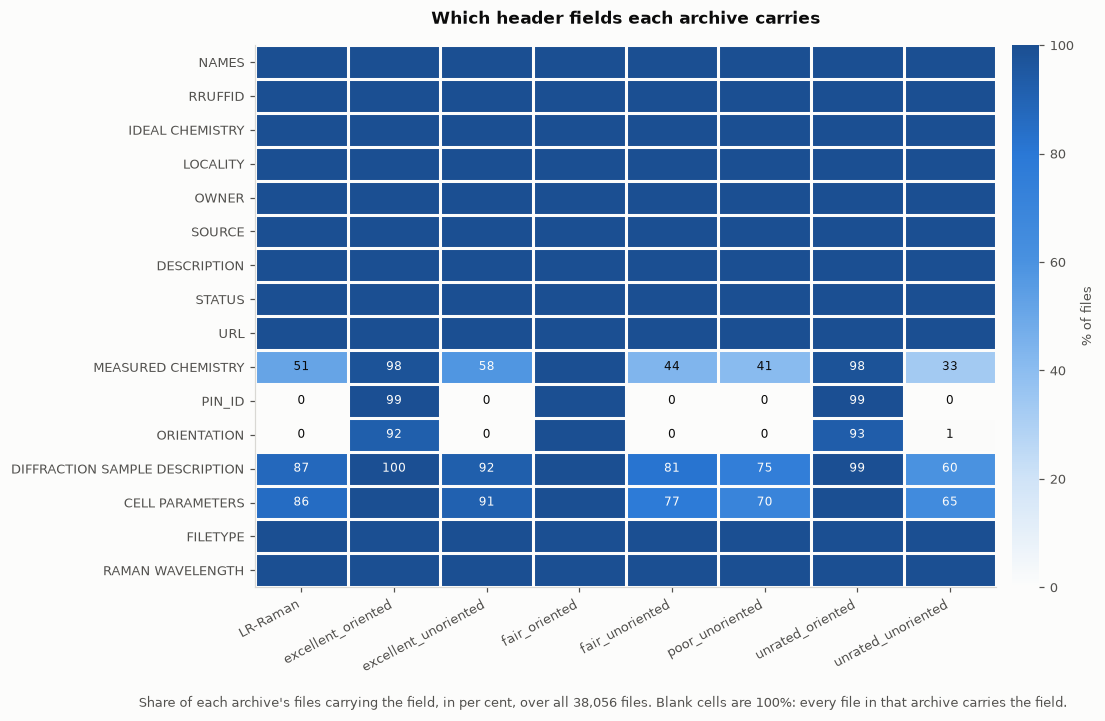

In [10]:
share_exact = presence.div(files, axis=1).mul(100)
share = share_exact.round(1)

fig, ax = plt.subplots(figsize=(9.2, 6.4))
image = ax.imshow(share_exact.values, cmap=SEQUENTIAL, vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(ARCHIVES)))
ax.set_xticklabels(ARCHIVES, rotation=28, ha="right")
ax.set_yticks(range(len(share)))
ax.set_yticklabels(share.index)
ax.set_xticks(np.arange(-0.5, len(ARCHIVES), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(share), 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)  # a surface gap between cells
ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
ax.set_title("Which header fields each archive carries", pad=14)

# Every cell is labelled except the complete ones, which are the rows a reader can skip
# without losing anything. The label is what keeps the light end of the ramp legible.
for row in range(share.shape[0]):
    for column in range(share.shape[1]):
        value = share_exact.values[row, column]
        if value < 99.95:
            ax.text(column, row, f"{value:.0f}", ha="center", va="center", fontsize=7.6,
                    color=INK if value < 55 else SURFACE)

bar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.02)
bar.set_label("% of files", color=INK_SOFT, fontsize=8.5)
bar.outline.set_visible(False)
fig.text(0.01, -0.06, f"Share of each archive's files carrying the field, in per cent, "
                      f"over all {len(index):,} files. Blank cells are 100%: every file "
                      f"in that archive carries the field.",
         color=INK_SOFT, fontsize=8.5)
fig.savefig(paths.output_path("rruff_eda_header_fields.png"), bbox_inches="tight")
plt.show()

Read the matrix by rows. `PIN_ID` and `ORIENTATION` are the two rows that are dark in
the oriented archives and empty in every unoriented one, which is the file contents
agreeing with the archive name about orientation. They are also the two rows that are
not quite complete inside the oriented archives: a small number of files in each lack
one or other of the two fields, and unrated_unoriented carries an `ORIENTATION` on a
handful of files despite being an unoriented archive. Code that decides orientation
from the directory name is therefore right about the archive and wrong about a few
files inside it, which the table above quantifies.

`MEASURED CHEMISTRY` is the most variable row, from 97.7% in the two oriented archives
down to 33.0% of unrated_unoriented, and its coverage tracks the same pattern as the
provenance rows: the better characterised an archive's samples, the more of the field is
filled in.

### The file name as a second, weaker index

Some of the same facts are repeated in the file name, which splits on `__` into eight
fields. Reading the name is convenient but less reliable than the header, so it is
worth knowing which field holds what.

In [11]:
NAME_FIELDS = {
    0: "mineral name", 1: "RRUFF id", 2: "spectrum type",
    3: "excitation wavelength", 4: "polarisation angle", 5: "direction",
    6: "RAW or Processed", 7: "content hash",
}

rows = []
for field, holds in NAME_FIELDS.items():
    values = Counter(name.split("__")[field] for name in index.name
                     if field < len(name.split("__")))
    # A long tail is summarised by its size rather than by its three largest members,
    # which say nothing useful about the field.
    common = ("too many to list" if len(values) > 60 else
              ", ".join(f"{value} ({count:,})" for value, count in values.most_common(3)))
    rows.append({"field": field, "holds": holds, "distinct": len(values),
                 "most common values": common})
pd.DataFrame(rows).set_index("field")

,holds,distinct,most common values
field,,,
0,mineral name,2511,too many to list
1,RRUFF id,5633,too many to list
2,spectrum type,2,"Raman (28,115), Broad_Scan (9,941)"
3,excitation wavelength,20,"532 (12,884), 514 (12,438), 780 (8,719)"
4,polarisation angle,24,"(16,644), 0 (9,941), 0-000 (5,655)"
5,direction,4,"(19,482), unoriented (9,945), ccw (5,816)"
6,RAW or Processed,3,"Raman_Data_Processed (17,382), Raman_Data_RAW ..."
7,content hash,38056,too many to list


In [12]:
# The name carries the same RAW/Processed split as the header, in its own spelling:
# LR-Raman writes Raman_Data_Raw where the other seven write Raman_Data_RAW.
from_name = index.name.str.split("__").str[6].fillna("").str.upper()
from_name = np.where(from_name.str.contains("RAW"), "RAW",
                     np.where(from_name.str.contains("PROCESSED"), "Processed", "other"))
print(f"file name and FILETYPE agree on "
      f"{(from_name == index.kind).sum():,} of {len(index):,} files")
print("distinct kind tokens in the file name:",
      dict(index.name.str.split("__").str[6].value_counts()))

file name and FILETYPE agree on 38,056 of 38,056 files
distinct kind tokens in the file name: {'Raman_Data_Processed': np.int64(17382), 'Raman_Data_RAW': np.int64(14108), 'Raman_Data_Raw': np.int64(6566)}


So the name agrees with `FILETYPE` on all 38056 files, but the seventh field is where
it lives and its spelling is not stable: LR-Raman writes `Raman_Data_Raw` in mixed case
where the other seven archives write `Raman_Data_RAW`. The second field is the other
place the pool divides, holding `Broad_Scan` for LR-Raman and `Raman` for everything
else, and the fifth holds `unoriented` in the LR-Raman set and in a handful of files
elsewhere. `FILETYPE`, and the header in general, is the field to read; the name is a
convenience that happens to line up.

## 5. RAW, Processed, and everything else

Each measurement can be exported twice: once as `Raman RAW`, the spectrum as the
instrument produced it, and once as `Raman Processed`, with the baseline corrected and
cosmic-ray spikes removed. Where both exist they sit in the same archive next to each
other. Not every measurement was exported twice, and the archives differ in how often it
happened, so the file counts below and the measurement counts after them say different
things.

In [13]:
kinds = index.pivot_table(index="archive", columns="kind", aggfunc="size", fill_value=0)
kinds = kinds.reindex(ARCHIVES)[["RAW", "Processed"]]
total = pd.DataFrame([{"RAW": int(kinds.RAW.sum()), "Processed": int(kinds.Processed.sum())}],
                     index=["all eight"])
kinds = pd.concat([kinds, total])
kinds["files"] = kinds.sum(axis=1)
kinds["RAW %"] = (kinds.RAW / kinds.files * 100).round(1)
kinds["Processed %"] = (kinds.Processed / kinds.files * 100).round(1)
kinds[["RAW", "Processed", "files"]] = kinds[["RAW", "Processed", "files"]].astype(int)

print(f"FILETYPE values in the pool, across all {len(index):,} files:")
for value, count in index.filetype.value_counts().items():
    print(f"   {count:7,}  {value!r}")
print()
print("There is no third kind of file. No archive ships anything other than a RAW or a")
print("Processed spectrum, so 'other' is empty everywhere in the pool.")
print()
kinds

FILETYPE values in the pool, across all 38,056 files:
    20,674  'Raman RAW'
    17,382  'Raman Processed'

There is no third kind of file. No archive ships anything other than a RAW or a
Processed spectrum, so 'other' is empty everywhere in the pool.



,RAW,Processed,files,RAW %,Processed %
LR-Raman,6566,3375,9941,66.0,34.0
excellent_oriented,3799,3869,7668,49.5,50.5
excellent_unoriented,5628,5787,11415,49.3,50.7
fair_oriented,12,13,25,48.0,52.0
fair_unoriented,1466,1485,2951,49.7,50.3
poor_unoriented,829,810,1639,50.6,49.4
unrated_oriented,1927,1851,3778,51.0,49.0
unrated_unoriented,447,192,639,70.0,30.0
all eight,20674,17382,38056,54.3,45.7


In [14]:
# The same files, grouped by measurement instead. An archive with an even RAW and
# Processed count can still ship most of its measurements only once, and this is the
# table that tells the two situations apart.
paired = index.groupby(["archive", "measurement"]).agg(
    files=("path", "size"), exports=("kind", "nunique"))
per_archive = pd.DataFrame({
    "files": index.groupby("archive").size(),
    "measurements": paired.files.groupby("archive").size(),
    "with both exports": paired.exports.groupby("archive").apply(lambda s: (s == 2).sum()),
}).reindex(ARCHIVES)
per_archive["one export only"] = per_archive.measurements - per_archive["with both exports"]
per_archive["both %"] = (per_archive["with both exports"] / per_archive.measurements * 100).round(1)
per_archive

,files,measurements,with both exports,one export only,both %
archive,,,,,
LR-Raman,9941,7719,2218,5501,28.7
excellent_oriented,7668,3871,3797,74,98.1
excellent_unoriented,11415,5805,5610,195,96.6
fair_oriented,25,13,12,1,92.3
fair_unoriented,2951,1497,1454,43,97.1
poor_unoriented,1639,890,749,141,84.2
unrated_oriented,3778,1928,1850,78,96.0
unrated_unoriented,639,462,175,287,37.9


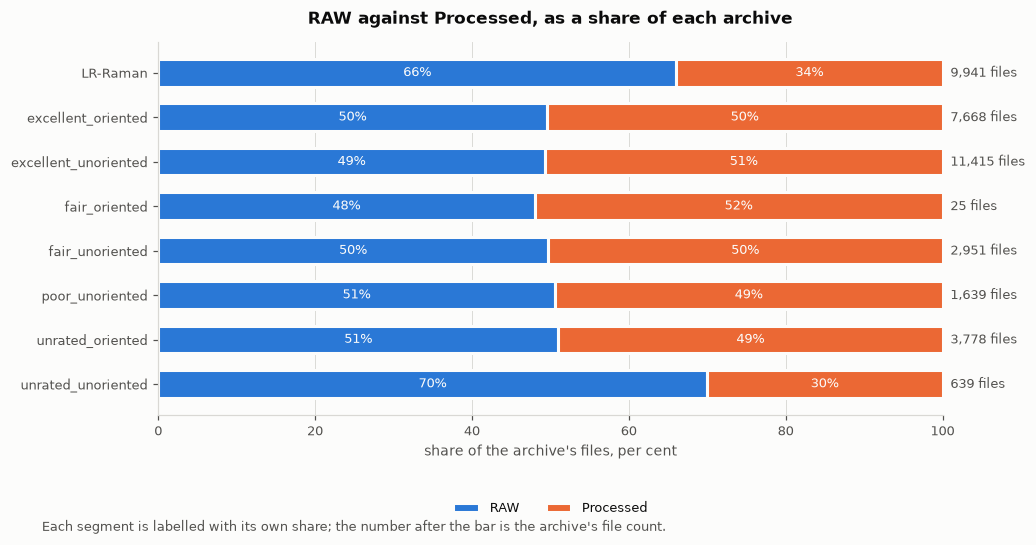

In [15]:
fig, ax = plt.subplots(figsize=(9.2, 4.4))
rows = np.arange(len(ARCHIVES))
raw = kinds.RAW.reindex(ARCHIVES).values
processed = kinds.Processed.reindex(ARCHIVES).values

# A share rather than a count: the archives run from 25 files to 11415, and on one
# linear axis the small ones would be unreadable slivers. Every archive gets the same
# width here and the file count rides at the end of its bar.
ax.barh(rows, raw / (raw + processed) * 100, height=0.62, color=BLUE, label="RAW",
        edgecolor=SURFACE, linewidth=2)  # the surface gap between segments
ax.barh(rows, processed / (raw + processed) * 100, left=raw / (raw + processed) * 100,
        height=0.62, color=ORANGE, label="Processed", edgecolor=SURFACE, linewidth=2)

for position, total in enumerate(raw + processed):
    raw_share = raw[position] / total * 100
    processed_share = 100 - raw_share
    ax.text(raw_share / 2, position, f"{raw_share:.0f}%", va="center", ha="center",
            fontsize=8.4, color=SURFACE)
    ax.text(raw_share + processed_share / 2, position, f"{processed_share:.0f}%",
            va="center", ha="center", fontsize=8.4, color=SURFACE)
    ax.text(101, position, f"{total:,} files", va="center", ha="left", fontsize=8.4,
            color=INK_SOFT)

ax.set_yticks(rows)
ax.set_yticklabels(ARCHIVES)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("share of the archive's files, per cent")
ax.grid(axis="y", visible=False)
ax.set_title("RAW against Processed, as a share of each archive", pad=12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncols=2, fontsize=8.5)
fig.text(0.01, -0.13, "Each segment is labelled with its own share; the number after "
                      "the bar is the archive's file count.", color=INK_SOFT, fontsize=8.5)
fig.savefig(paths.output_path("rruff_eda_raw_processed.png"), bbox_inches="tight")
plt.show()

Six of the eight archives sit within a point or two of an even split of RAW against
Processed files, which is what an archive of paired exports looks like at the file
level. **unrated_unoriented is the sharp exception** at 70% RAW against 30%, and
LR-Raman the milder one at 66 against 34; across the pool RAW files exceed Processed by
3292.

The measurement table is the one that matters, though, and it says something different.
An even file split does not mean the measurements were exported twice: LR-Raman splits
66 to 34 and has both exports for only 2218 of its 7719 measurements, because most of
its measurements were exported once, as RAW. The two oriented archives are the mirror
image, with both exports for 98% of their measurements, and unrated_unoriented pairs
only 175 of 462. So a pipeline that assumes every measurement arrives twice loses
different amounts of the pool in different archives, and the file counts do not warn it.

## 6. How RRUFF records the mineral identification

The label a classifier predicts is the mineral name in `NAMES`. What RRUFF records
about how sure it is of that name is the `STATUS` field, which is a sentence rather
than a code. Sixteen distinct sentences appear across the pool, and they group by what
the identification actually rests on:

| group | what the sentence says |
|---|---|
| **XRD plus chemistry** | confirmed by X-ray diffraction together with an analysis of the sample's composition |
| **XRD alone** | confirmed by X-ray diffraction only, including the single-crystal variants |
| **Non-X-ray only** | rests on something else: chemical analysis alone, Raman spectroscopy alone, or electron diffraction (EBSD, TEM, NMR) |
| **Not yet confirmed** | RRUFF records no confirmation at all |

The grouping is worth carrying through a pipeline because the last group is a different
kind of ground truth from the first three. A prediction error against a label RRUFF
does not stand behind is not the same error as one against a confirmed label, so
accuracy over a mixture of the two depends on how they were mixed.

In [16]:
counts = index.pivot_table(index="archive", columns="family", aggfunc="size",
                           fill_value=0).reindex(ARCHIVES)[FAMILIES]
family_share = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
family_share["files"] = counts.sum(axis=1)
family_share

family,XRD plus chemistry,XRD alone,Non-X-ray only,Not yet confirmed,files
archive,,,,,
LR-Raman,49.5,36.2,2.6,11.7,9941
excellent_oriented,97.7,2.3,0.0,0.0,7668
excellent_unoriented,56.8,33.9,2.0,7.3,11415
fair_oriented,100.0,0.0,0.0,0.0,25
fair_unoriented,41.4,37.2,2.8,18.6,2951
poor_unoriented,36.3,34.8,4.5,24.4,1639
unrated_oriented,97.7,2.3,0.0,0.0,3778
unrated_unoriented,30.7,33.5,16.3,19.6,639


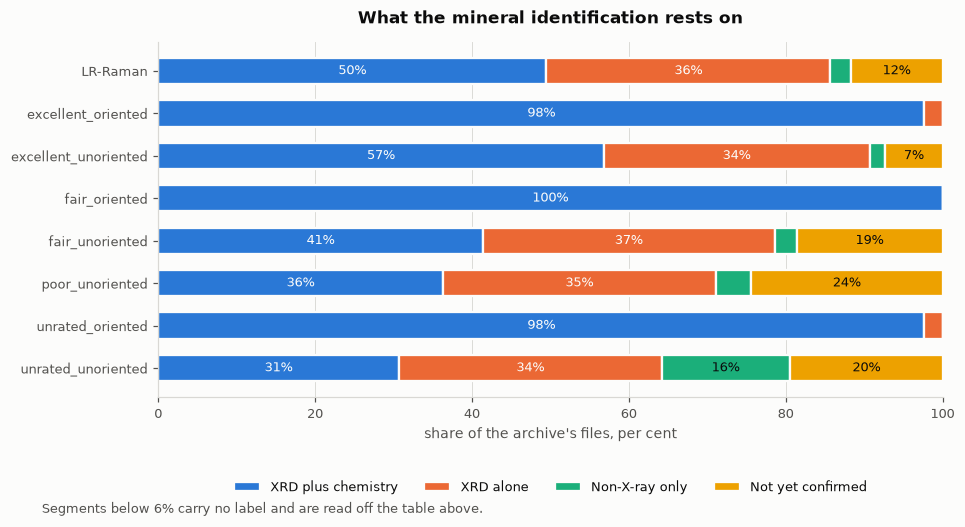

In [17]:
fig, ax = plt.subplots(figsize=(9.2, 4.2))
rows = np.arange(len(ARCHIVES))
left = np.zeros(len(ARCHIVES))

for family, colour in zip(FAMILIES, [BLUE, ORANGE, AQUA, YELLOW]):
    values = family_share[family].reindex(ARCHIVES).values
    ax.barh(rows, values, left=left, height=0.62, color=colour, label=family,
            edgecolor=SURFACE, linewidth=1.5)  # the surface gap between segments
    for position, width in enumerate(values):
        if width >= 6:  # a label only where it fits inside its segment
            ax.text(left[position] + width / 2, position, f"{width:.0f}%", va="center",
                    ha="center", fontsize=8.2,
                    color=SURFACE if colour in (BLUE, ORANGE) else INK)
    left += values

ax.set_yticks(rows)
ax.set_yticklabels(ARCHIVES)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("share of the archive's files, per cent")
ax.grid(axis="y", visible=False)
ax.set_title("What the mineral identification rests on", pad=12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncols=4, fontsize=8.5)
fig.text(0.01, -0.14, "Segments below 6% carry no label and are read off the table "
                      "above.", color=INK_SOFT, fontsize=8.5)
fig.savefig(paths.output_path("rruff_eda_identification.png"), bbox_inches="tight")
plt.show()

In [18]:
# The sixteen sentences verbatim, so the grouping can be checked against the words.
verbatim = index.pivot_table(index="status", columns="archive", aggfunc="size",
                             fill_value=0)
verbatim = verbatim.reindex(columns=ARCHIVES).fillna(0).astype(int)
verbatim["files"] = verbatim.sum(axis=1)
verbatim["group"] = [status_family(status) for status in verbatim.index]
verbatim = verbatim.sort_values("files", ascending=False)

confirmation = (index.assign(flag=index.family == "Not yet confirmed")
                .groupby("archive").flag.agg(["sum", "mean"]))
confirmation["mean"] = (confirmation["mean"] * 100).round(1)
print(f"files whose label RRUFF has not confirmed: "
      f"{int(confirmation['sum'].sum()):,} of {len(index):,} "
      f"({confirmation['sum'].sum() / len(index) * 100:.1f}%)")
print()
display(verbatim[["group", "files"] + ARCHIVES])

rests_on_raman = index.status.str.contains("Raman spectroscopy", case=False)
rests_on_raman &= ~index.status.str.contains("X-ray", case=False)
print(f"labels resting on Raman spectroscopy with no X-ray diffraction: "
      f"{int(rests_on_raman.sum())} files")
print(f"  of which Raman spectroscopy alone, with no other technique: "
      f"{int(index.status.str.contains('only by Raman', case=False).sum())} files")
print(f"  archives they appear in: {index.loc[rests_on_raman, 'archive'].nunique()}")

files whose label RRUFF has not confirmed: 3,072 of 38,056 (8.1%)



archive,group,files,LR-Raman,excellent_oriented,excellent_unoriented,fair_oriented,fair_unoriented,poor_unoriented,unrated_oriented,unrated_unoriented
status,,,,,,,,,,
The identification of this mineral has been confirmed by X-ray diffraction and chemical analysis,XRD plus chemistry,18519,2872,7101,4030,25,675,298,3427,91
The identification of this mineral is confirmed by single-crystal X-ray diffraction and chemical analysis,XRD plus chemistry,6112,2050,389,2459,0,547,297,265,105
The identification of this mineral has been confirmed by single-crystal X-ray diffraction,XRD alone,5064,1921,48,2183,0,550,251,40,71
The identification of this mineral has been confirmed only by single crystal X-ray diffraction,XRD alone,3012,1160,0,1249,0,385,165,0,53
The identification of this mineral is not yet confirmed,Not yet confirmed,3011,1144,0,829,0,547,398,0,93
The identification of this mineral has been confirmed by X-ray diffraction,XRD alone,1059,346,112,303,0,77,100,40,81
The identification of this mineral has been determined only by Raman spectroscopy,Non-X-ray only,400,136,0,141,0,29,11,0,83
The identification of this mineral has been made only by X-ray diffraction,XRD alone,310,106,12,100,0,54,27,4,7
The identification of this mineral has been confirmed only by chemical analysis,Non-X-ray only,297,114,0,72,0,43,61,0,7


labels resting on Raman spectroscopy with no X-ray diffraction: 418 files
  of which Raman spectroscopy alone, with no other technique: 400 files
  archives they appear in: 5


Two things stand out.

**The oriented archives contain no unconfirmed labels at all.** excellent_oriented and
unrated_oriented are the only archives where the last group is empty, and between them
they are 97.7% XRD-plus-chemistry. That follows from how the archives were built rather
than from the minerals in them: mounting a crystal on a pin for oriented work takes a
sample somebody has already characterised, so an unconfirmed sample does not reach the
oriented tier.

**The unconfirmed labels are concentrated in the unoriented archives**, and they are
not a rounding error: 24.4% of poor_unoriented, 19.6% of unrated_unoriented, 18.6% of
fair_unoriented and 7.3% of excellent_unoriented, against 11.7% of LR-Raman and none of
the oriented archives. Pool-wide, 3072 of 38056 files carry a label RRUFF does not stand
behind, one file in twelve.

A smaller number of labels rest on Raman spectroscopy alone, with no X-ray diffraction
at all. Those are worth separating out in any evaluation, because the label was assigned
from the same kind of measurement the model is being asked to make. The counts are
printed above, and they are small: 418 files across five archives, of which 400 are
Raman alone.

So a single accuracy figure over all eight archives mixes labels of two different
strengths, and for the poor and unrated archives the confirmed subset is the smaller
half. Reporting it separately is the honest way to present it.

## 7. The excitation wavelength

`RAMAN WAVELENGTH` records the laser used, in nanometres. It is a free-text field, so
it is read by taking the leading number rather than by parsing the field exactly, and
the values are then grouped onto the nearest of the seven lines RRUFF actually uses
(458, 488, 514.5, 532, 633, 780 and 785 nm), with anything more than 3.5 nm from all of
them left as `other`.

The grouping is not cosmetic. The common argon line is written `514` in 11716 files and
`514.5` in 23, and those are the same laser, so a distribution over the raw strings
would report the pool's second most common laser as a rare one. The same field also
carries the fiducial note wrapped onto its line on 728 files, which a reader taking the
value as a number would reject.

In [19]:
LASER_LINES = [458.0, 488.0, 514.5, 532.0, 633.0, 780.0, 785.0]


def laser_line(nm: float, tolerance: float = 3.5) -> str:
    """The laser line a reported wavelength belongs to, or 'other'/'unknown'."""
    if pd.isna(nm):
        return "unknown"
    nearest = min(LASER_LINES, key=lambda line: abs(line - nm))
    return f"{nearest:g}" if abs(nearest - nm) <= tolerance else "other"


index["laser"] = index.wavelength_nm.map(laser_line)
LASER_ORDER = ["458", "488", "514.5", "532", "633", "780", "785", "other", "unknown"]
LASER_ORDER = [line for line in LASER_ORDER if line in set(index.laser)]

laser_counts = index.pivot_table(index="archive", columns="laser", aggfunc="size",
                                 fill_value=0).reindex(ARCHIVES)
laser_counts = laser_counts.reindex(columns=LASER_ORDER, fill_value=0).astype(int)
laser_counts["files"] = laser_counts.sum(axis=1)
laser_counts.loc["all eight"] = laser_counts.sum()
laser_counts

laser,458,488,514.5,532,633,780,785,other,unknown,files
archive,,,,,,,,,,
LR-Raman,1,2,10,4920,8,3557,1442,0,1,9941
excellent_oriented,0,0,7657,3,2,0,6,0,0,7668
excellent_unoriented,2,0,798,5754,14,3380,1464,0,3,11415
fair_oriented,0,0,25,0,0,0,0,0,0,25
fair_unoriented,0,0,138,1357,4,915,530,3,4,2951
poor_unoriented,0,0,21,575,0,670,373,0,0,1639
unrated_oriented,0,0,3767,5,2,0,4,0,0,3778
unrated_unoriented,0,6,57,289,25,197,64,1,0,639
all eight,3,8,12473,12903,55,8719,3883,4,8,38056


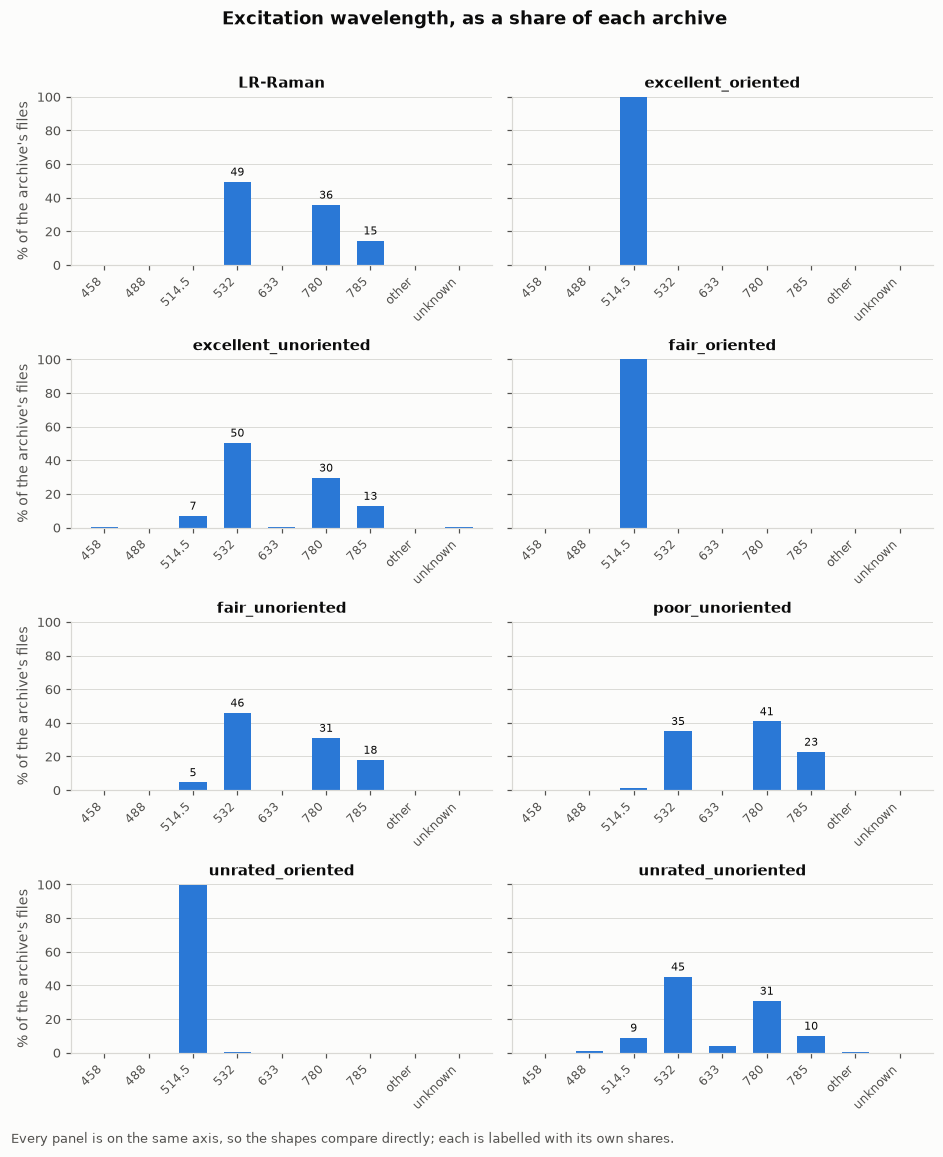

In [20]:
fig, axes = plt.subplots(4, 2, figsize=(8.6, 10.4), sharey=True)
for ax, archive in zip(axes.ravel(), ARCHIVES):
    row = laser_counts.loc[archive]
    values = (row[LASER_ORDER] / row["files"] * 100).values
    ax.bar(np.arange(len(LASER_ORDER)), values, color=BLUE, width=0.62)
    ax.set_title(archive, fontsize=9.5, pad=6)
    ax.set_xticks(np.arange(len(LASER_ORDER)))
    ax.set_xticklabels(LASER_ORDER, fontsize=7.6, rotation=45, ha="right")
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
    for position, value in enumerate(values):
        # The top of the axis is 100, so a label above a full-height bar would land on
        # the panel title; a bar that tall needs no label anyway.
        if 4 <= value < 97:
            ax.text(position, value + 2, f"{value:.0f}", ha="center", va="bottom",
                    fontsize=7.4, color=INK)

for ax in axes[:, 0]:
    ax.set_ylabel("% of the archive's files")
fig.suptitle("Excitation wavelength, as a share of each archive",
             fontsize=11.5, fontweight="bold", y=0.996)
fig.text(0.01, 0.006, "Every panel is on the same axis, so the shapes compare directly; "
                      "each is labelled with its own shares.",
         color=INK_SOFT, fontsize=8.5)
fig.tight_layout(rect=(0, 0.02, 1, 0.98))
fig.savefig(paths.output_path("rruff_eda_wavelengths.png"), bbox_inches="tight")
plt.show()

In [21]:
# The field verbatim, because the interesting part is how untidy it is. Only the values
# that are not a bare number are shown in full; those are the ones a strict reader would
# have to handle, and they are few enough to read.
values = index.wavelength_reported.value_counts()
bare = [value for value in values.index if NUMBER.fullmatch(value)]
odd = values.drop(index=bare)

print(f"distinct values of RAMAN WAVELENGTH in the pool: {len(values)}")
print(f"  a bare number: {len(bare)}, covering {int(values[bare].sum()):,} files "
      f"({values[bare].sum() / len(index) * 100:.2f}%)")
print(f"  anything else: {len(odd)}, covering {int(odd.sum())} files")
print()

# Which archive each odd value came from, to show that they are not a general problem.
where = index[index.wavelength_reported.isin(odd.index)]
pd.DataFrame({
    "files": odd,
    "archives": where.groupby("wavelength_reported").archive
                     .apply(lambda s: ", ".join(sorted(s.unique()))),
}).sort_values("files", ascending=False)

distinct values of RAMAN WAVELENGTH in the pool: 34
  a bare number: 15, covering 37,306 files (98.03%)
  anything else: 19, covering 750 files



,files,archives
wavelength_reported,,
514 Fiducial mark perpendicular to laser is parallel to b [0 1 0],224,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to -b [0 -1 0],160,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to a [1 0 0],88,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to c [0 0 1],80,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to -c [0 0 -1],48,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to b* (0 1 0),40,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to -a [-1 0 0],40,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to -b* (0 -1 0),32,"excellent_oriented, unrated_oriented"
514 Fiducial mark perpendicular to laser is parallel to [1 1 1],16,"excellent_oriented, unrated_oriented"


The pool runs on five lasers in practice. 532 nm is the most used, then the argon line
at 514.5 nm, then a near-infrared pair at 780 and 785 nm which RRUFF records as two
distinct values even though they are 5 nm apart. 633 nm is rare: 55 files in the whole
pool.

The values that are not a bare number are in three shapes, and the table above lists
every one of them. By far the largest is the fiducial note wrapped onto the wavelength's
line on 728 files, all of them in the two oriented archives, which is a by-product of how
the header wraps rather than a property of the laser. Then there are eight files reading
`unknown`, and fourteen carrying something else: `532 800, -`, `532 nm`, `458.5 nm`, and
a handful of instrument headers such as `532 X,Y` and `532 RamanShift_cm-1` pasted in
where the value belongs.

The distribution is not the same in every archive, and the difference follows the
orientation axis rather than the quality tier. The oriented archives are almost entirely
on the argon line (99.9% and 99.7% of files), because oriented work was done on one
instrument, while the unoriented archives are dominated by 532 nm and the 780/785 pair.
poor_unoriented is the clearest case: just 21 of its files, 1.3%, are on the argon line,
against 41% on 780 nm.

That matters when archives are combined. A spectrum's shape depends on the laser that
excited it, so a model trained across archives is partly being asked to learn which
laser was used, and a split that puts one laser in train and another in test measures
that instead of mineral identification.

## 8. The wavenumber axis is not shared

The last structural fact to check before any of these archives is combined: the
wavenumber axis is not the same from one archive to the next, in either its range or its
spacing. The broad-scan archive runs out to about 6600 cm-1, the oriented archives stop
near 1580, and the unoriented archives stop near 1300. Spacing divides along the same
line: the unoriented archives sample at about 0.48 cm-1, the oriented archives and the
broad scan at about 1.1 to 1.9 cm-1.

In [22]:
# The fraction of each file's own range that a fixed window would keep.
WINDOW = (313.3, 1028.4)  # the window the current training configuration uses
low = index.x_min.clip(lower=WINDOW[0])
high = index.x_max.clip(upper=WINDOW[1])
index["window_fraction"] = ((high - low).clip(lower=0)
                            / (index.x_max - index.x_min)).clip(0, 1)

spans = index.groupby("archive").agg(
    low_05=("x_min", lambda column: column.quantile(0.05)),
    low_median=("x_min", "median"),
    high_median=("x_max", "median"),
    high_95=("x_max", lambda column: column.quantile(0.95)),
    points_median=("points", "median"),
    spacing_median=("spacing", "median"),
    window_keep=("window_fraction", "median"),
).reindex(ARCHIVES)
print(f"a {WINDOW[0]:.1f} to {WINDOW[1]:.1f} cm-1 window keeps this much of each file:")
print(spans.window_keep.map(lambda value: f"{value:.1%}").to_string())
print(f"\nacross the pool, that window keeps {index.window_fraction.median():.1%} of a "
      f"file's range at the median")
spans.round(3)

a 313.3 to 1028.4 cm-1 window keeps this much of each file:
archive
LR-Raman                16.7%
excellent_oriented      49.9%
excellent_unoriented    61.0%
fair_oriented           52.7%
fair_unoriented         62.5%
poor_unoriented         62.3%
unrated_oriented        49.3%
unrated_unoriented      59.6%

across the pool, that window keeps 51.1% of a file's range at the median


,low_05,low_median,high_median,high_95,points_median,spacing_median,window_keep
archive,,,,,,,
LR-Raman,79.319,118.617,4381.445,6630.429,2228.0,1.928,0.167
excellent_oriented,49.365,102.428,1527.923,1572.435,1150.0,1.170,0.499
excellent_unoriented,87.582,119.978,1291.886,1515.648,2407.0,0.482,0.610
fair_oriented,83.137,179.505,1571.409,1577.018,1195.0,1.126,0.527
fair_unoriented,89.362,146.090,1286.228,1317.867,2361.0,0.482,0.625
poor_unoriented,89.301,137.388,1285.324,1312.564,2376.0,0.482,0.623
unrated_oriented,51.461,99.413,1570.384,1579.273,1275.0,1.132,0.493
unrated_unoriented,76.301,91.155,1300.660,2004.258,2477.0,0.482,0.596


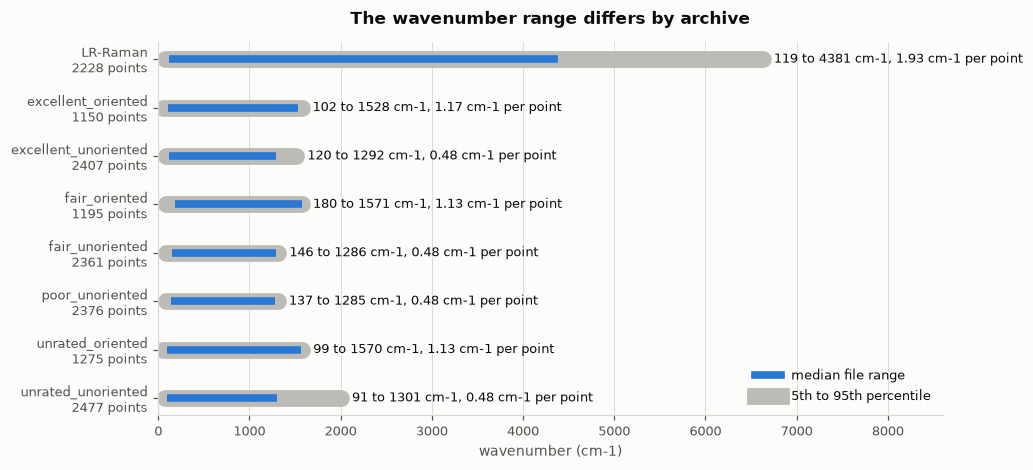

In [23]:
fig, ax = plt.subplots(figsize=(9.2, 4.4))
rows = np.arange(len(ARCHIVES))
for position, archive in enumerate(ARCHIVES):
    row = spans.loc[archive]
    # The percentile range is drawn wider than the median range so that the two read as
    # a nested pair even on the archives where the ranges nearly coincide; a narrower
    # grey band would be hidden underneath the blue on most rows.
    ax.plot([row.low_05, row.high_95], [position, position], color="#bdbbb5", linewidth=11,
            solid_capstyle="round", zorder=1)
    ax.plot([row.low_median, row.high_median], [position, position], color=BLUE,
            linewidth=5, solid_capstyle="butt", zorder=2)
    ax.text(row.high_95 + 120, position,
            f"{row.low_median:.0f} to {row.high_median:.0f} cm-1, "
            f"{row.spacing_median:.2f} cm-1 per point",
            va="center", ha="left", fontsize=8.2, color=INK)

ax.set_yticks(rows)
labels = [f"{archive}\n{spans.loc[archive, 'points_median']:.0f} points"
          for archive in ARCHIVES]
ax.set_yticklabels(labels, fontsize=8.2)
ax.invert_yaxis()
ax.set_xlabel("wavenumber (cm-1)")
ax.set_xlim(0, 8600)
ax.grid(axis="y", visible=False)
ax.set_title("The wavenumber range differs by archive", pad=12)
handles = [plt.Line2D([], [], color=BLUE, linewidth=5, label="median file range"),
           plt.Line2D([], [], color="#bdbbb5", linewidth=11,
                      label="5th to 95th percentile")]
ax.legend(handles=handles, loc="lower right", fontsize=8.5)
fig.savefig(paths.output_path("rruff_eda_axes.png"), bbox_inches="tight")
plt.show()

A model that takes a fixed-length window as input is therefore choosing which parts of
which archives it can see. The 313 to 1028 cm-1 window used above keeps about half of a
file's range across the pool, but only a sixth of it in the broad scan, which is where
the extra range lives. Whatever window is chosen, the spectra have to be resampled onto a
grid first, because the native spacing differs by a factor of four between the broad scan
(1.93 cm-1 per point) and the unoriented archives (0.48), and by a factor of 2.4 between
the oriented archives (about 1.13) and the unoriented ones.

## 9. What this means for training

Three of the findings above change what a model trained on this pool can claim.

**The pool is internally duplicated.** Every measurement that was exported twice has two
files carrying one label, and those two files differ only in the export kind and the
content hash of the name. Grouping the 38056 files on the name without those two fields
gives 21930 measurements, of which 16085 ship both exports, so 32219 files have a twin
somewhere in the pool. Any split that holds out files rather than measurements leaves
the twin of the held-out item in the training set.

In [24]:
# Pooling across archives on purpose: the same measurement does appear in more than one
# archive, and the leak crosses the archive boundary too.
sizes = index.groupby("measurement").size()
kinds_per_measurement = index.groupby("measurement").kind.nunique()
with_twin = sizes[sizes > 1]
across = index.groupby("measurement").archive.nunique()

print(f"{len(index):,} files in the pool")
print(f"{len(sizes):,} measurements, keyed by the name without its export kind and hash")
print(f"  shipping both exports: {int((kinds_per_measurement == 2).sum()):,} "
      f"({(kinds_per_measurement == 2).mean() * 100:.1f}%)")
print(f"  shipping one export:   {int((kinds_per_measurement == 1).sum()):,}")
print(f"files that have a twin in the pool: {int(with_twin.sum()):,} "
      f"({with_twin.sum() / len(index) * 100:.1f}% of files)")
print(f"measurements appearing in more than one archive: {int((across > 1).sum()):,}")
print()

archives_of = index.groupby("rruff_id").archive.nunique()
print(f"{index.rruff_id.nunique():,} RRUFF ids")
print(f"  measured in more than one archive: {(archives_of > 1).sum():,} "
      f"({(archives_of > 1).mean() * 100:.1f}%)")
print(f"  measured in all eight:             {(archives_of == 8).sum():,}")
per_id = index.groupby(["archive", "rruff_id"]).measurement.nunique()
print("\nmeasurements of one sample inside one archive, most in any archive:")
print(per_id.groupby("archive").max().reindex(ARCHIVES).to_string())

38,056 files in the pool
21,930 measurements, keyed by the name without its export kind and hash
  shipping both exports: 16,085 (73.3%)
  shipping one export:   5,845
files that have a twin in the pool: 32,219 (84.7% of files)
measurements appearing in more than one archive: 254

4,153 RRUFF ids
  measured in more than one archive: 3,974 (95.7%)
  measured in all eight:             0

measurements of one sample inside one archive, most in any archive:
archive
LR-Raman                 4
excellent_oriented      56
excellent_unoriented     6
fair_oriented            4
fair_unoriented          5
poor_unoriented          5
unrated_oriented        24
unrated_unoriented       4


The twin relation is exact: two files are twins when that key matches, and the largest
group of twins in the pool is four files rather than two, so the same measurement was
sometimes exported as RAW twice. Grouping on the measurement removes the twin leak. It
does not remove the second one, which is visible in the last table: one sample can be
measured up to 56 times inside one archive, at different orientations, and those are
different measurements of the same crystal rather than the same measurement twice.

So there are two levels to choose between, and they answer different questions. Grouping
on the measurement answers *can the model recognise a spectrum it has not been shown*.
Grouping on the RRUFF id answers *can the model identify a sample it has not been shown*,
which is the harder and more useful question, but it puts every orientation of a crystal
on one side of the split and so makes the test set smaller. Either is defensible;
holding out files is not, because it leaks by construction on 85% of the pool.

**The archives differ in what they are made of.** The two oriented archives cover 216
and 217 mineral names across 7668 and 3778 files, a median of 24 and 12 files per name,
so a handful of names supply a large share of each. The unoriented archives cover far
more names with far fewer files each, and 103 of the 271 names in unrated_unoriented
appear exactly once. A sample drawn evenly from the pool is therefore not drawn evenly
from the minerals, and the archives a model is trained on decide which minerals it can
ever have seen.

**Roughly one label in twelve is one RRUFF does not stand behind**, and they sit almost
entirely in the unoriented archives while the oriented archives have none. A single
accuracy figure over a mixture of the two depends on the mixture, so the confirmed
labels have to be reported on their own.

## 10. Reproducing

The notebook needs the eight archive directories under `~/Desktop`, or `RRUFF_DESKTOP`
set to wherever they are. Nothing else is read from disk, and running every cell takes
about half a minute, most of it the one cell that reads all 38056 files.

The five figures are written to `outputs/rruff_eda_*.png` through `src.paths.output_path`,
so a re-run overwrites them in place rather than leaving stale copies under another
name.

Executing the notebook from a script needs the `notebooks` extra, which carries the
packages that run a notebook (`nbformat`, `nbclient`, `ipykernel`) alongside torch:

```
.venv/bin/python -m pip install -e ".[notebooks]"
.venv/bin/python -m nbclient notebooks/rruff_eda.ipynb --kernel-name sh_project
```